# **k-Neareset Neighbors & Locally-Weighted Regression**

In this notebook we will look at **k-Neareset Neighbors** and **Locally-Weighted Regression**. We will start with the regression task and after that look at classification task.

Do some imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor
# https://scikit-learn.org/dev/modules/generated/sklearn.neighbors.KNeighborsRegressor.html
from sklearn.neighbors import KNeighborsClassifier
# https://scikit-learn.org/dev/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

from sklearn.preprocessing import StandardScaler
# https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling

from matplotlib.colors import ListedColormap

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import mean_squared_error, ConfusionMatrixDisplay, precision_recall_curve
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score

# **Part 1: REGRESSION**

The data.

In [2]:
np.random.seed(42)
n = 100
X = 6 * np.random.rand(n, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(n, 1)

Create the model.

In [3]:
knn = KNeighborsRegressor(n_neighbors=10)
#knn = KNeighborsRegressor(n_neighbors=10, weights='distance')
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


Plot it.

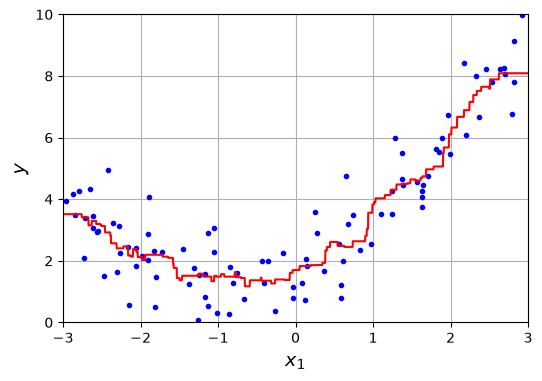

In [4]:
X_plot = np.linspace(-3, 3, 5000).reshape(5000, 1)
yHat = knn.predict(X_plot)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_plot, yHat, "r-")
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

Evaluate it.

In [5]:
cv_results = cross_validate(knn, X, y, cv=10, scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
print('MAE: ', -cv_results['test_neg_mean_absolute_error'].mean())
print('RMSE:', -cv_results['test_neg_root_mean_squared_error'].mean())
print('R2:  ', cv_results['test_r2'].mean())

MAE:  0.7811714259928344
RMSE: 0.9666231234958109
R2:   0.7751700932717377


Plot training and validation curves depending on $k$.

k= 1	MSE_train=0.000		MSE_validation=1.497
k= 2	MSE_train=0.363		MSE_validation=1.249
k= 3	MSE_train=0.528		MSE_validation=1.097
k= 4	MSE_train=0.606		MSE_validation=1.104
k= 5	MSE_train=0.667		MSE_validation=1.047
k= 6	MSE_train=0.706		MSE_validation=1.015
k= 7	MSE_train=0.716		MSE_validation=1.009
k= 8	MSE_train=0.732		MSE_validation=1.012
k= 9	MSE_train=0.788		MSE_validation=1.002
k=10	MSE_train=0.783		MSE_validation=0.982
k=11	MSE_train=0.800		MSE_validation=0.989
k=12	MSE_train=0.805		MSE_validation=0.948
k=13	MSE_train=0.807		MSE_validation=0.921
k=14	MSE_train=0.799		MSE_validation=0.946
k=15	MSE_train=0.799		MSE_validation=0.962
k=16	MSE_train=0.805		MSE_validation=0.965
k=17	MSE_train=0.829		MSE_validation=0.997
k=18	MSE_train=0.831		MSE_validation=1.054
k=19	MSE_train=0.872		MSE_validation=1.118
k=20	MSE_train=0.909		MSE_validation=1.189


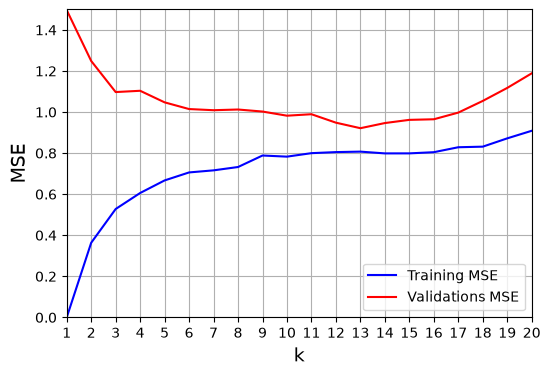

In [6]:
max_k = 20
MSEs_train = np.empty(max_k)
MSEs_validation = np.empty(max_k)

for k in range(1, max_k+1):
  knn = KNeighborsRegressor(n_neighbors=k)

  knn.fit(X, y)
  yHat = knn.predict(X)
  MSE_train = mean_squared_error(y, yHat)
  MSEs_train[k - 1] = MSE_train

  #yHat = cross_val_predict(knn, X, y, cv=10)
  #MSE_validation = mean_squared_error(y, yHat)
  MSE_validation = -cross_validate(knn, X, y, cv=10, scoring=["neg_mean_squared_error"])['test_neg_mean_squared_error'].mean()
  print('k=%2d\tMSE_train=%.3f\t\tMSE_validation=%.3f' % (k, MSE_train, MSE_validation))
  MSEs_validation[k - 1] = MSE_validation

plt.figure(figsize=(6, 4))
plt.plot(range(1,k+1), MSEs_train, 'b-', label='Training MSE')
plt.plot(range(1,k+1), MSEs_validation, 'r-', label='Validations MSE')
plt.xlabel('k', fontsize=14)
plt.ylabel('MSE', fontsize=14)
plt.legend(loc='lower right')
plt.axis([1, max_k, 0, 1.5])
plt.xticks(range(1, max_k+1))
plt.grid()
plt.show()

## **Our own implementation of KNN**

In [7]:
# import BaseEstimator for inheritance
from sklearn.base import BaseEstimator

# define our new class for KNN
class KNN(BaseEstimator):
  # initialization function for setting KNN parameters
  def __init__(self, k=10, weighted=False):
    self.k = k
    self.weighted = weighted

  # function for "fitting" our model. no actual fitting is done because this is KNN
  def fit(self, X, y):
    self.X = X
    self.y = y

  # function for prediction where the actual work is happening
  def predict(self, Xq):
    # the number of query data points
    n = len(Xq)
    # the array which we will fill with predicted values
    yHat = np.zeros(n)

    # loop through all query points. q is query index
    for q in range(0, n):
      # one current query point for which we will do prediction
      xquery = Xq[q, :]

      # compute distances from the query point to all training data points
      #dists = np.sqrt(np.sum((xquery - self.X) ** 2, axis=1))
      dists = np.linalg.norm(xquery - self.X, axis=1)

      # find k nearest neighbors using the computed distances
      idx = np.argsort(dists)
      idx = idx[:self.k]
      yNeighbors = self.y[idx]

      # compute weighted or unweighted prediction and store it in the yHat array
      if self.weighted:
        dists += 1e-8
        weights = 1 / dists[idx]
        yHat[q] = np.sum(yNeighbors.squeeze() * weights) / np.sum(weights)
      else:
        yHat[q] = np.mean(yNeighbors)

    # return the array of predictions
    return yHat

In [8]:
knn = KNN(k=10)
#knn = KNN(k=10, weighted=True)
knn.fit(X, y)

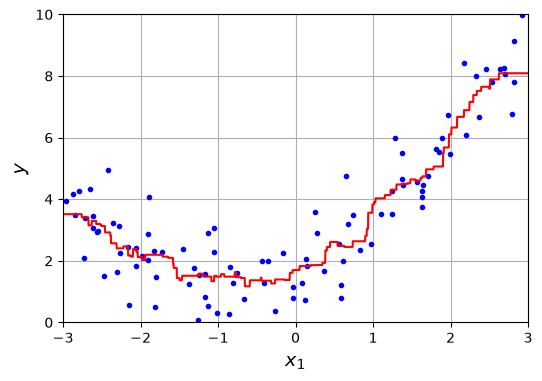

In [9]:
X_plot = np.linspace(-3, 3, 5000).reshape(5000, 1)
yHat = knn.predict(X_plot)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_plot, yHat, "r-")
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [10]:
cv_results = cross_validate(knn, X, y, cv=10, scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
print('MAE: ', -cv_results['test_neg_mean_absolute_error'].mean())
print('RMSE:', -cv_results['test_neg_root_mean_squared_error'].mean())
print('R2:  ', cv_results['test_r2'].mean())

MAE:  0.7811714259928344
RMSE: 0.9666231234958109
R2:   0.7751700932717377


## **Our own implementation of LWR (Locally-Weighted Regression)**

In [11]:
# import BaseEstimator for inheritance
from sklearn.base import BaseEstimator
from sklearn.linear_model import LinearRegression

# define our new class for KNN
class LWR(BaseEstimator):
  # initialization function for setting KNN parameters
  def __init__(self, k=10, weighted=False):
    self.k = k
    self.weighted = weighted
    self.lin_reg = LinearRegression()

  # function for "fitting" our model. no actual fitting is done because this is KNN
  def fit(self, X, y):
    self.X = X
    self.y = y

  # function for prediction where the actual work is happening
  def predict(self, Xq):
    # the number of query data points
    n = len(Xq)
    # the array which we will fill with predicted values
    yHat = np.zeros(n)

    # loop through all query points. q is query index
    for q in range(0, n):
      # one current query point for which we will do prediction
      xquery = Xq[q, :].reshape(1, -1)

      # compute distances from the query point to all training data points
      #dists = np.sqrt(np.sum((xquery - self.X) ** 2, axis=1))
      dists = np.linalg.norm(xquery - self.X, axis=1)

      # find k nearest neighbors using the computed distances
      idx = np.argsort(dists)
      idx = idx[:self.k]

      # compute weighted or unweighted prediction and store it in the yHat array
      if self.weighted:
        #dists += 1e-8
        weights = np.abs(dists[idx] / np.max(dists[idx]))
        # compute Tricube weighting (other weightings available)
        which = weights < 1
        weights[which] = np.power(1 - np.power(weights[which], 3), 3)
        weights[~which] = 0
        # fit linear regression and predict
        self.lin_reg.fit(self.X[idx, :], self.y[idx], weights)
        yHat[q] = self.lin_reg.predict(xquery).squeeze()
      else:
        # fit linear regression and predict
        self.lin_reg.fit(self.X[idx, :], self.y[idx])
        yHat[q] = self.lin_reg.predict(xquery).squeeze()

    # return the array of predictions
    return yHat

In [12]:
lwr = LWR(k=10)
#lwr = LWR(k=10, weighted=True)
lwr.fit(X, y)

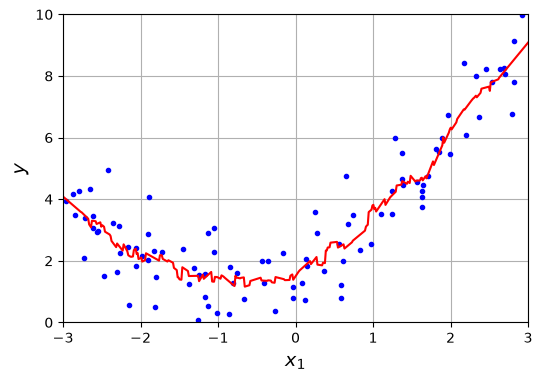

In [13]:
X_plot = np.linspace(-3, 3, 500).reshape(500, 1)
yHat = lwr.predict(X_plot)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_plot, yHat, "r-")
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [14]:
cv_results = cross_validate(lwr, X, y, cv=10, scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
print('MAE: ', -cv_results['test_neg_mean_absolute_error'].mean())
print('RMSE:', -cv_results['test_neg_root_mean_squared_error'].mean())
print('R2:  ', cv_results['test_r2'].mean())

MAE:  0.7836964289818755
RMSE: 0.9791048029282823
R2:   0.7609153107074983


---
# **Part 2: CLASSIFICATION**

For this notebook we will use the **Iris dataset**.

In [15]:
from sklearn.datasets import load_iris
iris = load_iris()

For demonstration purposes, we will work only with the third column (petal length) and will make it into a binary classification task: Virginica vs. Others.

In [16]:
X = iris.data[:, 3].reshape(-1, 1)  # take third column and reshape to get a column vector
y = iris.target_names[iris.target] == 'virginica'  # make it into binary classification with Virginica vs. Others

Create k-NN model.

In [17]:
knn = KNeighborsClassifier(n_neighbors=10)
#knn = KNeighborsClassifier(n_neighbors=10, weights='distance')
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[bool](2,)","[False, True]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Plot it.

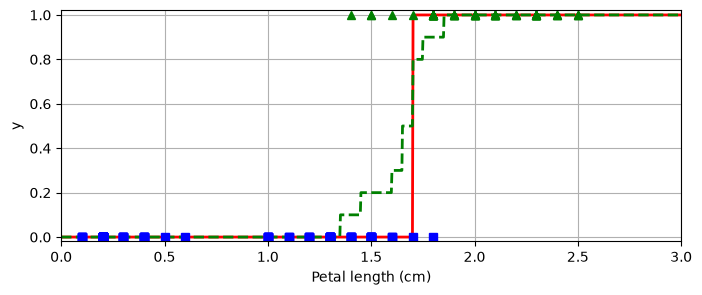

In [18]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = knn.predict_proba(X_new)
yHat = knn.predict(X_new)

plt.figure(figsize=(8, 3))
plt.plot(X_new, yHat, "r", linewidth=2)
plt.plot(X_new, y_proba[:, 1], "g--", linewidth=2)

plt.plot(X[y == 0], y[y == 0], "bs")
plt.plot(X[y == 1], y[y == 1], "g^")
plt.xlabel("Petal length (cm)")
plt.ylabel("y")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

Evaluate it.

In [19]:
skfcv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    "accuracy": make_scorer(
        accuracy_score
    ),
    "precision_macro": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score, average="macro", zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
}

cv_results = cross_validate(knn, X, y, cv=skfcv, scoring=scoring)
print('Accuracy:        ', cv_results['test_accuracy'].mean())
print('Macro Precision: ', cv_results['test_precision_macro'].mean())
print('Macro Recall:    ', cv_results['test_recall_macro'].mean())
print('Macro F1:        ', cv_results['test_f1_macro'].mean())

Accuracy:         0.9600000000000002
Macro Precision:  0.9637878787878789
Macro Recall:     0.95
Macro F1:         0.9528410040252145


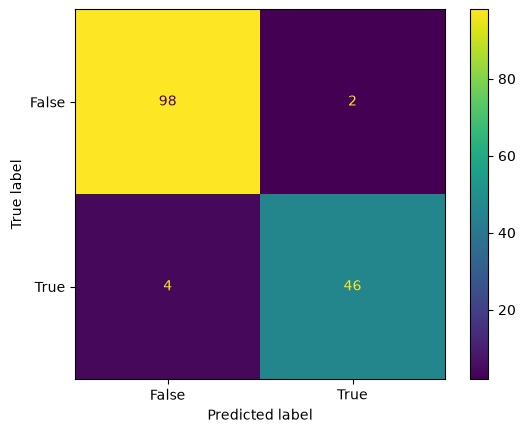

In [20]:
yHat = cross_val_predict(knn, X, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat)

## **Precision/Recall Trade-off**

To plot Precision and Recall, we will be using `cross_val_predict` with the `predict_proba` function to compute probability of Class 1 for each data point.

In [21]:
y_prob = cross_val_predict(knn, X, y, cv=10, method="predict_proba")[:, 1]

Now we can use those probabilities to get Precisions and Recalls for all possible thresholds.

In [22]:
precisions, recalls, thresholds = precision_recall_curve(y, y_prob)

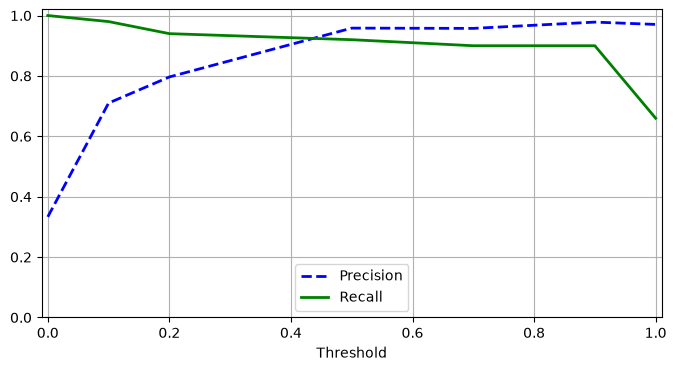

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="lower center")
plt.axis([-0.01, 1.01, 0, 1.02])
plt.show()

Now let's plot the Precision-Recall curve.

It is desired that a model should have both high Precision and high Recall. However, most of the time it involves a trade-off between the two.

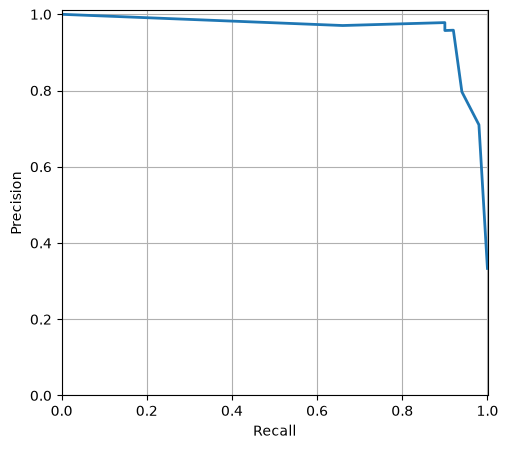

In [24]:
plt.figure(figsize=(5.5, 5))
plt.plot(recalls, precisions, linewidth=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1.001, 0, 1.01])
plt.grid()
plt.show()

# **KNN with two features**

For this demonstration, we will take features 2 and 3.

In [25]:
X = iris.data[:, (2, 3)]
y = iris.target_names[iris.target] == 'versicolor'

And we will standardize the data.

In [26]:
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Create a model.

In [27]:
knn = KNeighborsClassifier(n_neighbors=10)
#knn = KNeighborsClassifier(n_neighbors=10, weights='distance')
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[bool](2,)","[False, True]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Plot it.

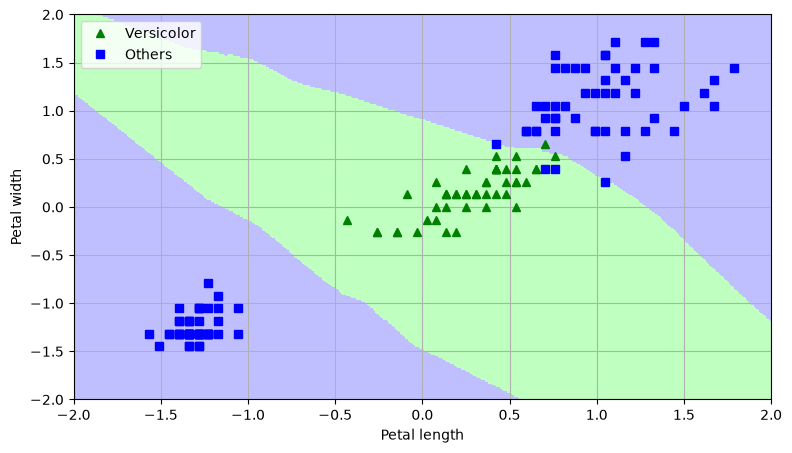

In [28]:
# to plot the decision boundaries, we have to create a grid of x0,x1 values
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

# predict y for each x0,x1 and reshape back to grid
zz = knn.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Others")

custom_cmap = ListedColormap(["#bfbfff", "#bfffbf"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

Evaluate it.

In [29]:
cv_results = cross_validate(knn, X, y, cv=skfcv, scoring=scoring)
print('Accuracy:        ', cv_results['test_accuracy'].mean())
print('Macro Precision: ', cv_results['test_precision_macro'].mean())
print('Macro Recall:    ', cv_results['test_recall_macro'].mean())
print('Macro F1:        ', cv_results['test_f1_macro'].mean())

Accuracy:         0.9600000000000002
Macro Precision:  0.9578354978354978
Macro Recall:     0.96
Macro F1:         0.9559975696817802


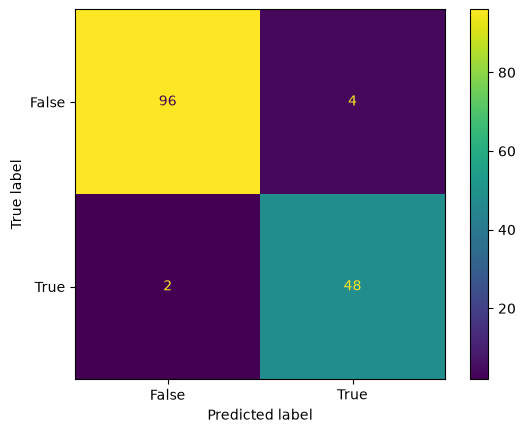

In [30]:
yHat = cross_val_predict(knn, X, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat)

# **KNN with all three classes**

Now let's try the same processing with all three classes that the dataset offers.

In [31]:
X = iris.data[:, (2, 3)]
y = iris.target

scaler = StandardScaler().fit(X)
X = scaler.transform(X)

In [32]:
knn = KNeighborsClassifier(n_neighbors=10)
#knn = KNeighborsClassifier(n_neighbors=10, weights='distance')
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


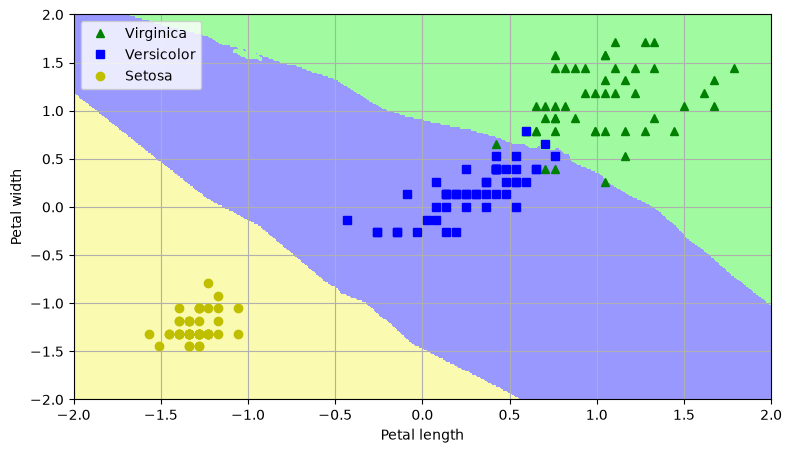

In [33]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

zz =  knn.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Setosa")

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [34]:
cv_results = cross_validate(knn, X, y, cv=skfcv, scoring=scoring)
print('Accuracy:        ', cv_results['test_accuracy'].mean())
print('Macro Precision: ', cv_results['test_precision_macro'].mean())
print('Macro Recall:    ', cv_results['test_recall_macro'].mean())
print('Macro F1:        ', cv_results['test_f1_macro'].mean())

Accuracy:         0.9600000000000002
Macro Precision:  0.9660317460317461
Macro Recall:     0.96
Macro F1:         0.9593097643097643


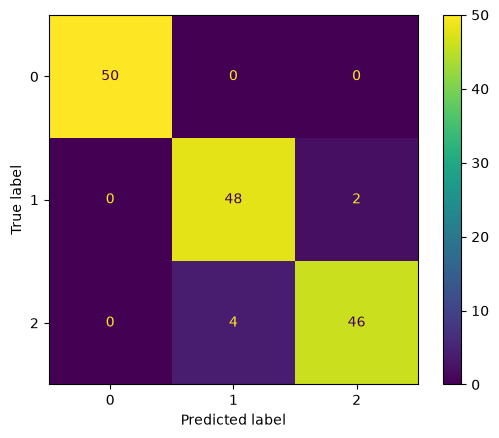

In [35]:
yHat = cross_val_predict(knn, X, y, cv=skfcv)
ConfusionMatrixDisplay.from_predictions(y, yHat)

<br>
<br>
<br>
<br>
<br>
<br>

---
<small>*Notebook by Gints Jēkabsons. Some parts of the code are based on the book <a href="https://www.oreilly.com/library/view/hands-on-machine-learning/9781098125967/" target="_blank">“Hands-On Machine Learning”</a> and it's <a href="https://github.com/ageron/handson-ml3" target="_blank">GitHub repo.</a>*</small>